# Análise do dataset, dos resultados e da importância das features

**Dataset:** [Adult Census Income](https://www.kaggle.com/datasets/uciml/adult-census-income) · **Modelo:** rede neural MLP escolhida na [bancada de testes](bancada_redes_neurais_adult.ipynb) · **Tarefa:** prever se a renda anual é maior que 50 mil dólares (`>50K`).

Este notebook complementa a bancada de testes em três partes:

1. **Características do dataset** — gráficos de como cada variável se relaciona com a renda;
2. **Principais resultados** — o que a bancada mostrou e como a rede final se comporta no teste;
3. **Importância das features** — quais variáveis a rede mais usa e como cada uma afeta a previsão.

## Bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.calibration import calibration_curve
from sklearn.metrics import (ConfusionMatrixDisplay, f1_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

import bancada as bc   # código da bancada (bancada.py, na mesma pasta)

RANDOM_STATE = bc.RANDOM_STATE
pd.set_option("display.width", 200)

# Paleta categórica validada para daltonismo + tons de texto/grade
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA_TEXTO, CINZA_GRADE, CINZA_CLARO = "#52514e", "#e4e3df", "#b9b8b2"
COR_CLASSE = {"<=50K": AZUL, ">50K": LARANJA}
# Escala sequencial de um só tom (azul), do claro ao escuro
AZUIS = LinearSegmentedColormap.from_list("azuis", ["#f3f7fd", "#9cc2ef", "#2a78d6", "#123f75"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CINZA_TEXTO, "axes.labelcolor": CINZA_TEXTO,
    "xtick.color": CINZA_TEXTO, "ytick.color": CINZA_TEXTO,
    "axes.grid": True, "grid.color": CINZA_GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 10,
    "axes.titlesize": 11, "axes.titlelocation": "left",
})

## Dados

Mesma carga e mesma divisão treino/teste (80/20, estratificada, semente 42) da bancada de testes.

In [2]:
df = bc.carregar_dados()
df["renda"] = np.where(df["income"] == ">50K", ">50K", "<=50K")
alvo = (df["income"] == ">50K").astype(int)
TAXA_GERAL = alvo.mean()

X, y = bc.separar_x_y(df.drop(columns=["renda"]))
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Treino:", X_treino.shape, " Teste:", X_teste.shape)

Dados carregados de: espelho UCI no GitHub (mesmas linhas do Kaggle) -> 32561 linhas, 15 colunas
Treino: (26048, 14)  Teste: (6513, 14)


# Parte 1 — Características do dataset

## 1.1 Variável alvo

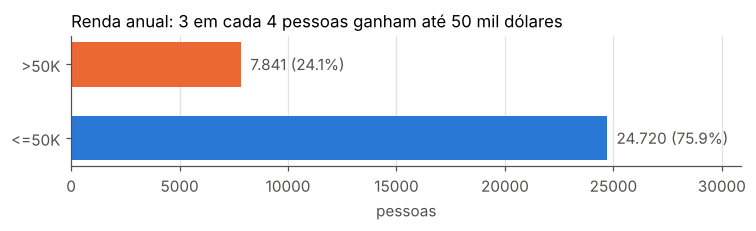

In [3]:
contagem = df["renda"].value_counts()
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(contagem.index, contagem.values, color=[COR_CLASSE[c] for c in contagem.index], height=0.6)
for i, (classe, n) in enumerate(contagem.items()):
    ax.annotate(f"{n:,} ({n / len(df):.1%})".replace(",", "."), (n, i), xytext=(6, 0),
                textcoords="offset points", va="center", color=CINZA_TEXTO)
ax.set(title="Renda anual: 3 em cada 4 pessoas ganham até 50 mil dólares", xlabel="pessoas",
       xlim=(0, contagem.max() * 1.25))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Análise:** o alvo é desbalanceado: 75,9% `<=50K` e 24,1% `>50K`. Um modelo que sempre respondesse `<=50K` já teria 76% de acurácia; por isso, além da acurácia, acompanhamos precisão, recall, F1 e as áreas sob as curvas ROC e precisão-recall.

## 1.2 Valores faltantes

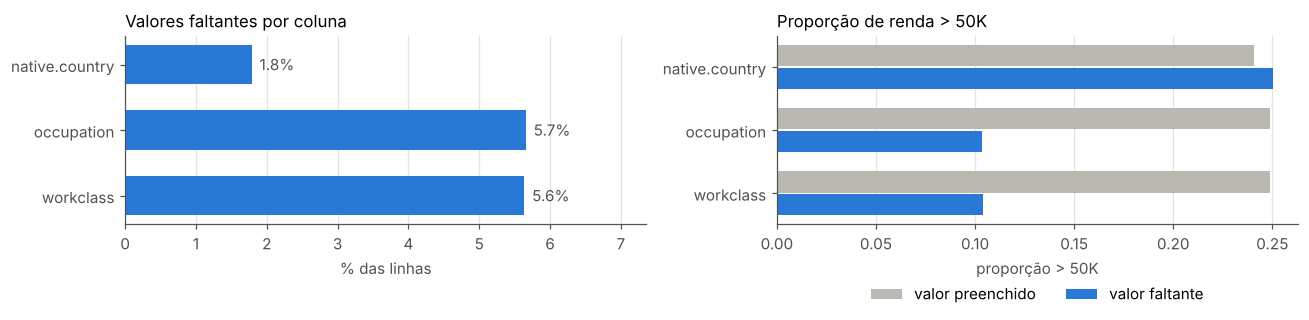

In [4]:
colunas_faltantes = ["workclass", "occupation", "native.country"]
pct = df[colunas_faltantes].isna().mean() * 100
taxa_faltante = [alvo[df[c].isna()].mean() for c in colunas_faltantes]
taxa_preenchido = [alvo[df[c].notna()].mean() for c in colunas_faltantes]

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.2))
eixos[0].barh(colunas_faltantes, pct.values, color=AZUL, height=0.6)
for i, v in enumerate(pct.values):
    eixos[0].annotate(f"{v:.1f}%", (v, i), xytext=(5, 0), textcoords="offset points", va="center", color=CINZA_TEXTO)
eixos[0].set(title="Valores faltantes por coluna", xlabel="% das linhas", xlim=(0, pct.max() * 1.3))
eixos[0].grid(axis="y", visible=False)

pos = np.arange(len(colunas_faltantes))
eixos[1].barh(pos + 0.18, taxa_preenchido, height=0.34, color=CINZA_CLARO, label="valor preenchido")
eixos[1].barh(pos - 0.18, taxa_faltante, height=0.34, color=AZUL, label="valor faltante")
eixos[1].set_yticks(pos, colunas_faltantes)
eixos[1].set(title="Proporção de renda > 50K", xlabel="proporção > 50K")
eixos[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
eixos[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Análise:** os faltantes são poucos (5,6% em `workclass`, 5,7% em `occupation` e 1,8% em `native.country`). `workclass` e `occupation` faltam **nas mesmas 1.836 linhas** (mais 7 pessoas que nunca trabalharam, sem ocupação). Nessas linhas a proporção de renda alta é de 10%, contra 25% no restante: o fato de faltar é, por si só, um sinal de renda baixa. Já em `native.country` o faltante não muda nada (25% × 24%).

## 1.3 Variáveis numéricas por classe de renda

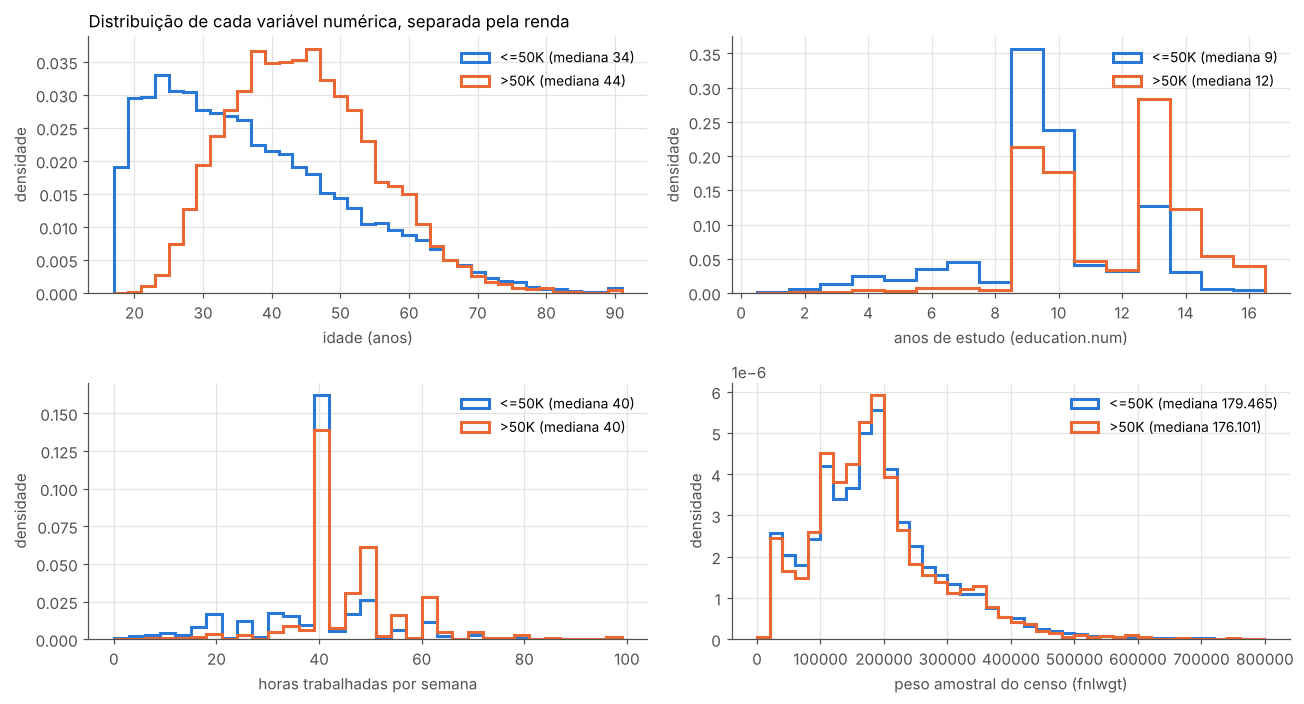

In [5]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 6.5))
config = [("age", "idade (anos)", np.arange(17, 92, 2)),
          ("education.num", "anos de estudo (education.num)", np.arange(0.5, 17.5, 1)),
          ("hours.per.week", "horas trabalhadas por semana", np.arange(0, 101, 3)),
          ("fnlwgt", "peso amostral do censo (fnlwgt)", np.linspace(0, 800_000, 41))]
for ax, (col, rotulo, bins) in zip(eixos.ravel(), config):
    for classe in ["<=50K", ">50K"]:
        valores = df.loc[df["renda"] == classe, col]
        ax.hist(valores, bins=bins, density=True, histtype="step", linewidth=2,
                color=COR_CLASSE[classe], label=f"{classe} (mediana {valores.median():,.0f})".replace(",", "."))
    ax.set(xlabel=rotulo, ylabel="densidade")
    ax.legend(frameon=False, fontsize=9)
eixos[0, 0].set_title("Distribuição de cada variável numérica, separada pela renda")
plt.tight_layout()
plt.show()

**Análise:**

- **Idade:** quem ganha `>50K` é mais velho (mediana de 44 anos contra 34). Quase ninguém com menos de 25 anos tem renda alta; a renda alta se concentra entre 35 e 60 anos.
- **Escolaridade:** mediana de 12 anos de estudo para `>50K` contra 9 para `<=50K`. A partir de 13 anos (bacharelado), as pessoas de renda alta passam a ser maioria nas barras.
- **Horas por semana:** as duas classes têm mediana de 40 horas, mas quem ganha `>50K` aparece mais nas jornadas de 45 a 60 horas, e quem ganha menos domina as jornadas parciais (menos de 35 horas).
- **`fnlwgt`:** as duas distribuições são praticamente iguais. É um peso amostral do censo, não uma característica da pessoa, e não deve ajudar a prever a renda.

## 1.4 Ganho e perda de capital

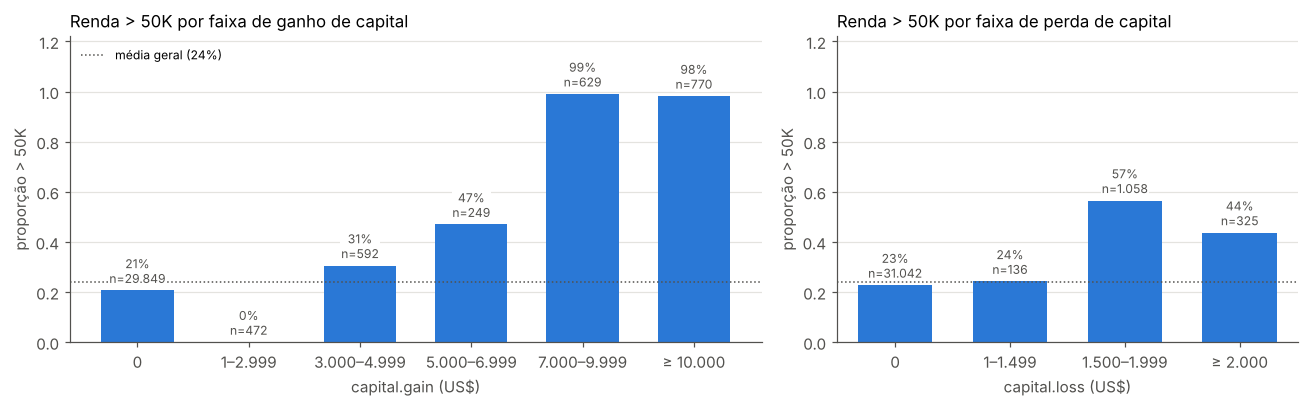

In [6]:
faixas = [-1, 0, 2_999, 4_999, 6_999, 9_999, 100_000]
nomes = ["0", "1–2.999", "3.000–4.999", "5.000–6.999", "7.000–9.999", "≥ 10.000"]
faixa_ganho = pd.cut(df["capital.gain"], faixas, labels=nomes)
resumo = pd.DataFrame({"pessoas": faixa_ganho.value_counts(sort=False),
                       "taxa": alvo.groupby(faixa_ganho, observed=False).mean()})

faixas_p = [-1, 0, 1_499, 1_999, 5_000]
nomes_p = ["0", "1–1.499", "1.500–1.999", "≥ 2.000"]
faixa_perda = pd.cut(df["capital.loss"], faixas_p, labels=nomes_p)
resumo_p = pd.DataFrame({"pessoas": faixa_perda.value_counts(sort=False),
                         "taxa": alvo.groupby(faixa_perda, observed=False).mean()})

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 2]})
for ax, r, titulo, xlabel in [(eixos[0], resumo, "Renda > 50K por faixa de ganho de capital", "capital.gain (US$)"),
                              (eixos[1], resumo_p, "Renda > 50K por faixa de perda de capital", "capital.loss (US$)")]:
    ax.bar(r.index.astype(str), r["taxa"], color=AZUL, width=0.65)
    ax.axhline(TAXA_GERAL, color=CINZA_TEXTO, ls=":", lw=1)
    for i, (taxa, n) in enumerate(zip(r["taxa"], r["pessoas"])):
        ax.annotate(f"{taxa:.0%}\nn={n:,}".replace(",", "."), (i, taxa), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8, color=CINZA_TEXTO,
                    bbox={"fc": "white", "ec": "none", "pad": 0.5})
    ax.set(title=titulo, xlabel=xlabel, ylabel="proporção > 50K", ylim=(0, 1.22))
    ax.grid(axis="x", visible=False)
eixos[0].lines[0].set_label(f"média geral ({TAXA_GERAL:.0%})")
eixos[0].legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Análise:** 92% das pessoas têm ganho de capital zero, e a relação com a renda é **em degraus, não linear**:

- ganhos pequenos (1 a 2.999 dólares, 472 pessoas) têm 0% de renda alta — menos ainda que quem não tem ganho (21%);
- entre 3.000 e 6.999 a proporção sobe para 31% a 47%;
- a partir de 7.000 dólares, praticamente todos (98% a 99%) ganham `>50K`.

A perda de capital segue um padrão parecido: entre 1.500 e 1.999 dólares, 57% têm renda alta. Isso explica dois resultados da bancada: o indicador "tem ganho de capital" ajudou a rede, e o logaritmo nas colunas de capital **piorou** — ele aproxima valores como 2.000 e 8.000, que estão em lados opostos desse degrau.

## 1.5 Variáveis categóricas

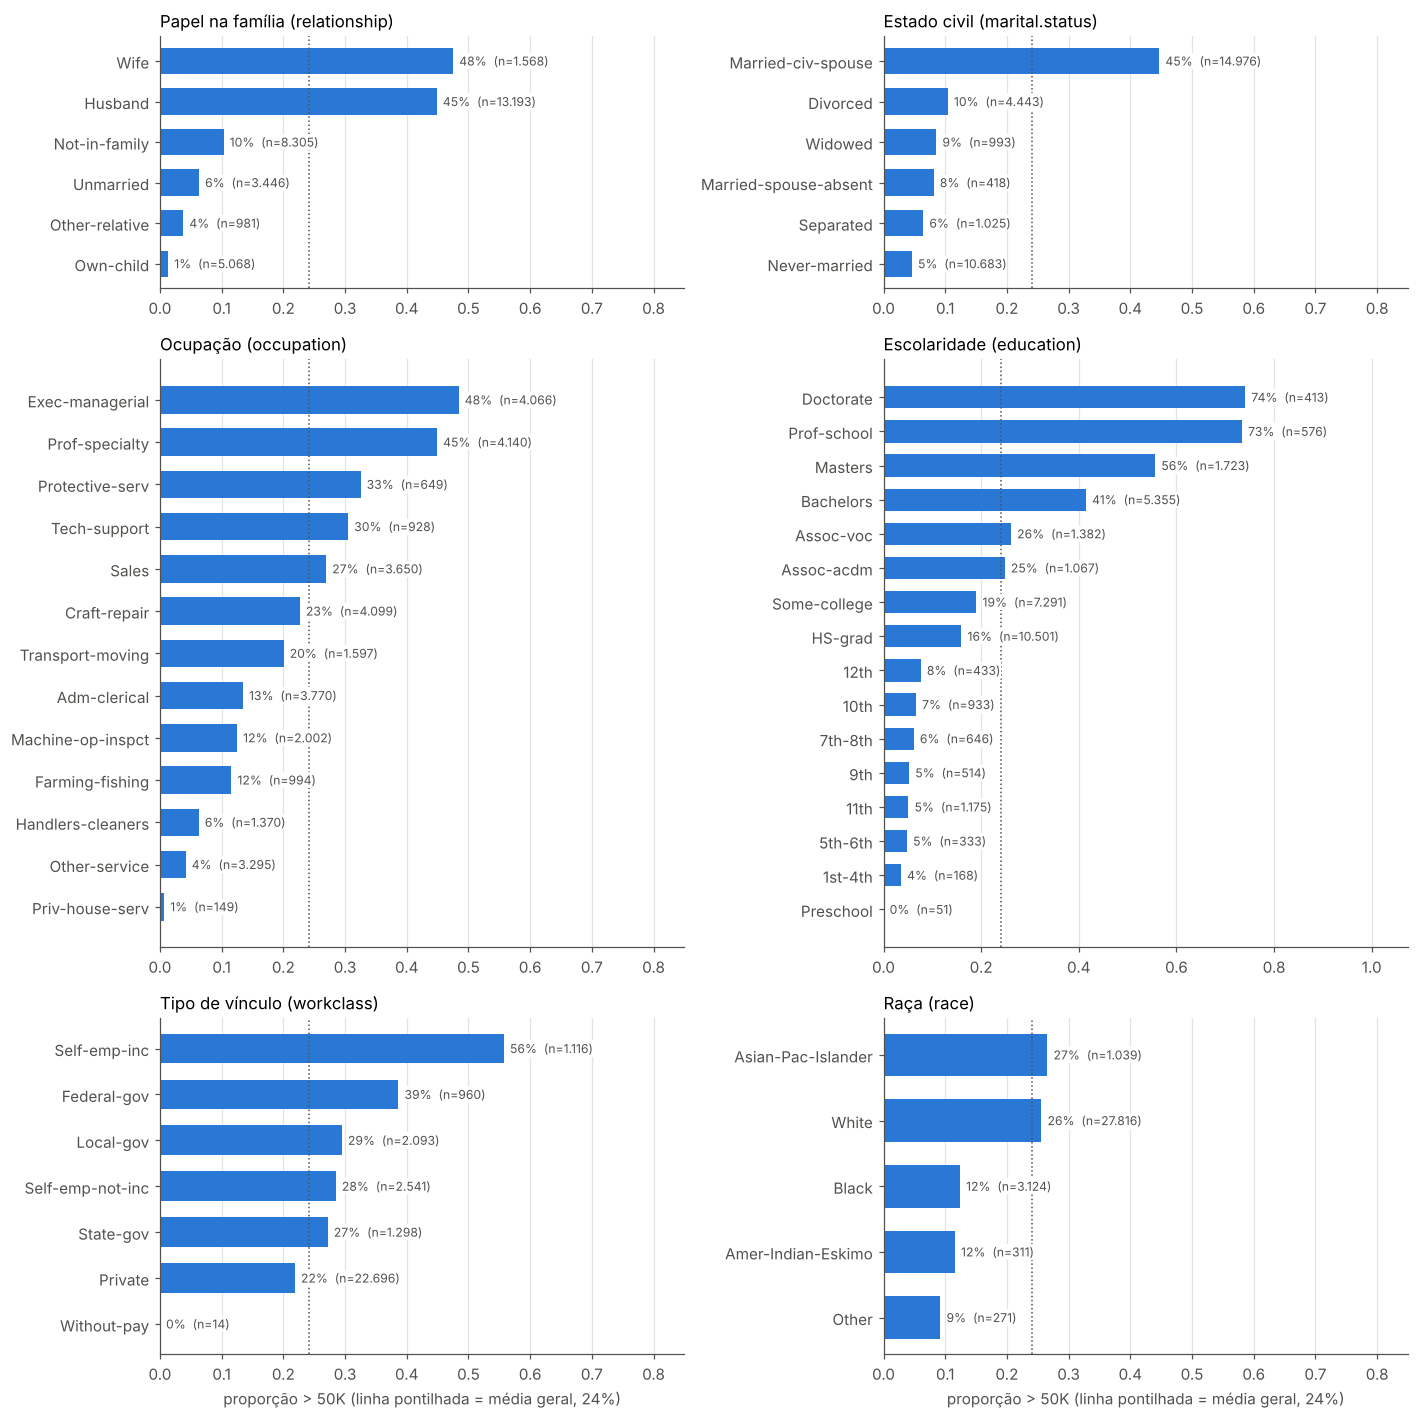

In [7]:
def taxa_por_categoria(coluna, minimo=50):
    g = df.groupby(coluna)["income"].agg(pessoas="size", taxa=lambda s: (s == ">50K").mean())
    return g[g["pessoas"] >= minimo].sort_values("taxa")

def barras_taxa(ax, coluna, titulo, minimo=50):
    t = taxa_por_categoria(coluna, minimo)
    ax.barh(t.index, t["taxa"], color=AZUL, height=0.65)
    ax.axvline(TAXA_GERAL, color=CINZA_TEXTO, ls=":", lw=1)
    for i, (taxa, n) in enumerate(zip(t["taxa"], t["pessoas"])):
        ax.annotate(f"{taxa:.0%}  (n={n:,})".replace(",", "."), (taxa, i), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=8, color=CINZA_TEXTO,
                    bbox={"fc": "white", "ec": "none", "pad": 0.5})
    ax.set(title=titulo, xlim=(0, max(0.85, t["taxa"].max() * 1.45)))
    ax.grid(axis="y", visible=False)

fig, eixos = plt.subplots(3, 2, figsize=(13, 13), gridspec_kw={"height_ratios": [6, 14, 8]})
barras_taxa(eixos[0, 0], "relationship", "Papel na família (relationship)")
barras_taxa(eixos[0, 1], "marital.status", "Estado civil (marital.status)")
barras_taxa(eixos[1, 0], "occupation", "Ocupação (occupation)")
barras_taxa(eixos[1, 1], "education", "Escolaridade (education)")
barras_taxa(eixos[2, 0], "workclass", "Tipo de vínculo (workclass)", minimo=10)
barras_taxa(eixos[2, 1], "race", "Raça (race)")
for ax in eixos[-1]:
    ax.set_xlabel("proporção > 50K (linha pontilhada = média geral, 24%)")
plt.tight_layout()
plt.show()

**Análise:**

- **Família e estado civil** separam muito bem as classes: pessoas casadas (`Married-civ-spouse`, `Husband`, `Wife`) têm 45% a 48% de renda alta, enquanto solteiros, divorciados e filhos que moram com os pais (`Own-child`, mediana de 22 anos) ficam entre 1% e 10%.
- **Ocupação:** cargos de gestão (`Exec-managerial`, 48%) e profissões especializadas (`Prof-specialty`, 45%) contra serviços domésticos e gerais (1% a 4%).
- **Escolaridade:** cresce de forma contínua, de 0% a 8% (sem ensino médio completo) até 73% a 74% (doutorado e escolas profissionais), passando por 16% no ensino médio e 41% no bacharelado.
- **Tipo de vínculo:** donos de empresa (`Self-emp-inc`, 56%) e funcionários federais (39%) estão acima da média; o setor privado, com 70% das pessoas, fica em 22%.
- **Raça:** brancos e asiáticos ficam em 26% a 27%; negros, indígenas e outros, em 9% a 12%.

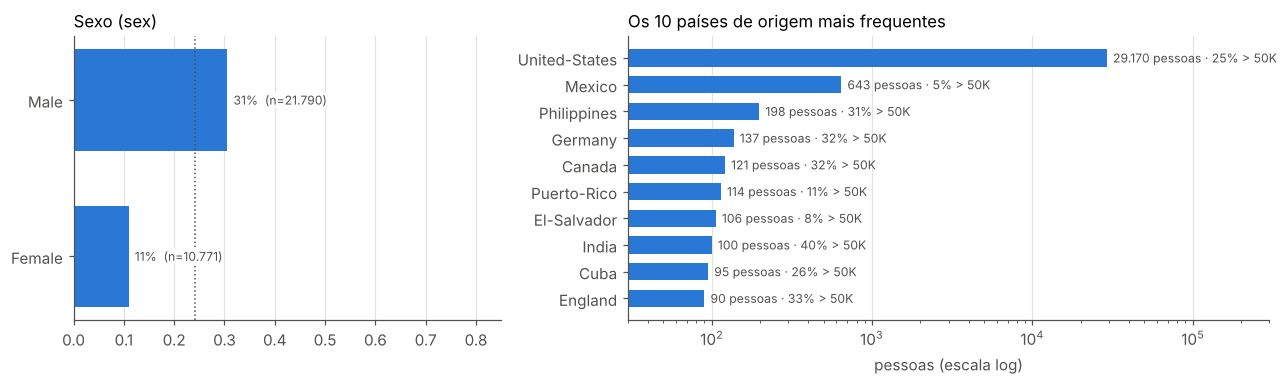

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 3]})
barras_taxa(eixos[0], "sex", "Sexo (sex)")
# Países: os EUA concentram ~90% das pessoas; mostramos os 10 mais frequentes
top = df["native.country"].value_counts().head(10).index
t = (df[df["native.country"].isin(top)].groupby("native.country")["income"]
     .agg(pessoas="size", taxa=lambda s: (s == ">50K").mean()).sort_values("pessoas"))
eixos[1].barh(t.index, t["pessoas"], color=AZUL, height=0.65)
eixos[1].set_xscale("log")
for i, (n, taxa) in enumerate(zip(t["pessoas"], t["taxa"])):
    eixos[1].annotate(f"{n:,} pessoas · {taxa:.0%} > 50K".replace(",", "."), (n, i), xytext=(4, 0),
                      textcoords="offset points", va="center", fontsize=8, color=CINZA_TEXTO)
eixos[1].set(title="Os 10 países de origem mais frequentes", xlabel="pessoas (escala log)", xlim=(30, 3e5))
eixos[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Análise:** a proporção de renda alta entre homens (31%) é quase o triplo da das mulheres (11%) — uma desigualdade presente nos dados do censo de 1994 que o modelo pode aprender e reproduzir (ver a análise por grupo na Parte 2). Quanto ao país de origem, 90% das pessoas nasceram nos EUA; os outros 41 países têm poucas pessoas cada, com proporções muito variadas (5% no México, 40% na Índia), o que dá pouca informação confiável ao modelo.

## 1.6 Interação entre idade e escolaridade

A proporção de renda alta depende da **combinação** de variáveis: cresce com a escolaridade, mas só a partir de certa idade.

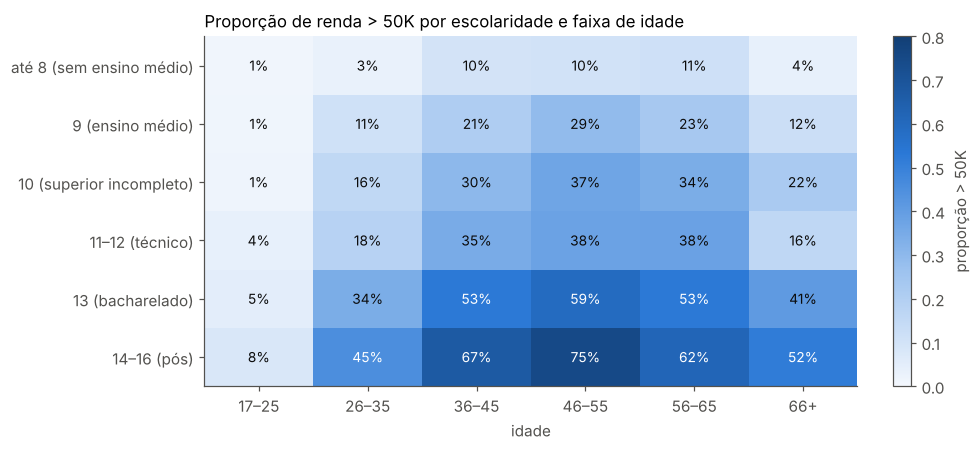

In [9]:
faixa_idade = pd.cut(df["age"], [16, 25, 35, 45, 55, 65, 91], labels=["17–25", "26–35", "36–45", "46–55", "56–65", "66+"])
faixa_estudo = pd.cut(df["education.num"], [0, 8, 9, 10, 12, 13, 16],
                      labels=["até 8 (sem ensino médio)", "9 (ensino médio)", "10 (superior incompleto)",
                              "11–12 (técnico)", "13 (bacharelado)", "14–16 (pós)"])
mapa = alvo.groupby([faixa_estudo, faixa_idade], observed=False).mean().unstack()
n = alvo.groupby([faixa_estudo, faixa_idade], observed=False).size().unstack()

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(mapa.values, cmap=AZUIS, vmin=0, vmax=0.8, aspect="auto")
ax.set_xticks(range(mapa.shape[1]), mapa.columns)
ax.set_yticks(range(mapa.shape[0]), mapa.index)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.0%}" if n.values[i, j] >= 30 else "–", ha="center", va="center",
                fontsize=9, color="white" if v > 0.45 else "#0b0b0b")
ax.grid(False)
ax.set(title="Proporção de renda > 50K por escolaridade e faixa de idade", xlabel="idade")
fig.colorbar(im, ax=ax, label="proporção > 50K", fraction=0.04)
plt.tight_layout()
plt.show()

**Análise:** o efeito da escolaridade depende da idade. Até 25 anos, a renda alta é rara em qualquer nível de estudo (no máximo 8%). Com pós-graduação, a proporção salta para 45% entre 26 e 35 anos e chega a 75% entre 46 e 55 anos; com até 8 anos de estudo, nunca passa de 11%. Depois dos 65 anos, a proporção cai em todos os níveis (aposentadoria). Esse tipo de **interação** é o que uma rede neural consegue modelar sem que seja preciso criá-la à mão — o que explica por que as features de interação testadas na bancada quase não ajudaram.

## 1.7 Associação entre as variáveis

Para variáveis categóricas usamos o **V de Cramér** (0 = nenhuma associação, 1 = uma determina a outra). As numéricas foram divididas em 10 faixas (decis) para entrar na mesma medida. A última linha mostra a associação de cada variável com a renda.

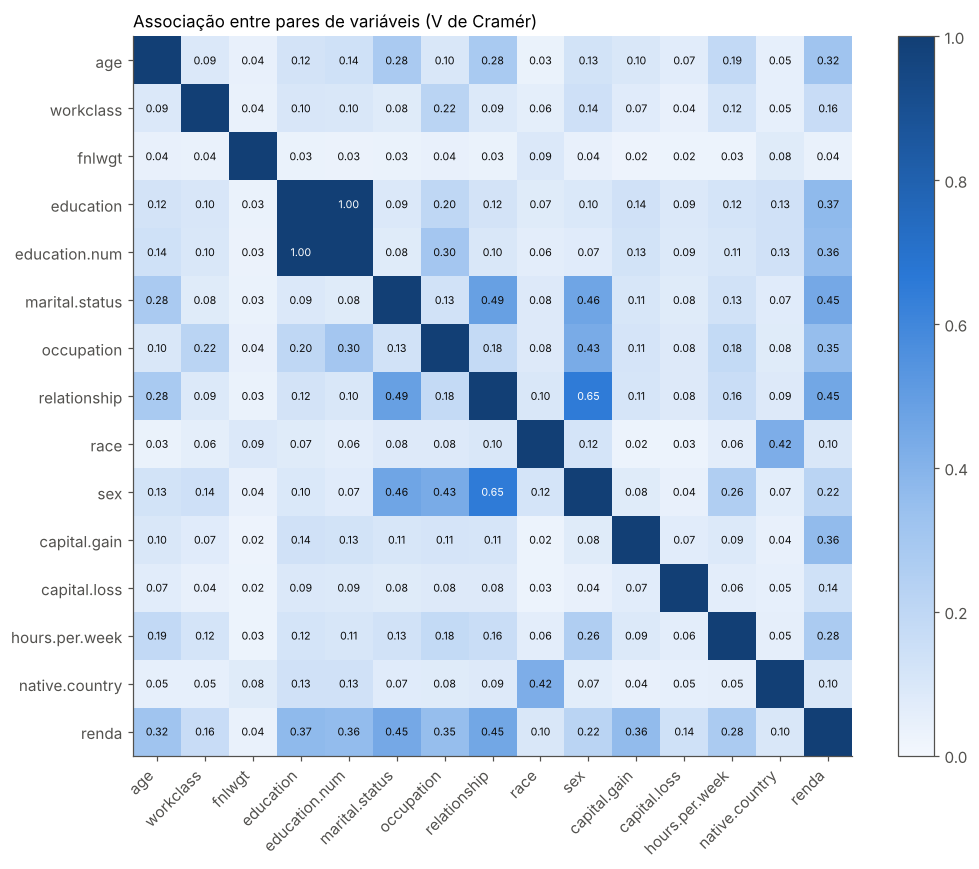

Associação de cada variável com a renda:
relationship      0.454
marital.status    0.447
education         0.369
capital.gain      0.360
education.num     0.358
occupation        0.349
age               0.319
hours.per.week    0.275
sex               0.216
workclass         0.164
capital.loss      0.139
race              0.101
native.country    0.100
fnlwgt            0.037


In [10]:
def v_de_cramer(a, b):
    tabela = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabela, correction=False)[0]
    r, k = tabela.shape
    return np.sqrt(chi2 / (tabela.values.sum() * (min(r, k) - 1)))

dados = df.drop(columns=["income", "renda"]).copy()
for col in bc.COLUNAS_NUMERICAS:
    if col in ("capital.gain", "capital.loss"):
        dados[col] = pd.cut(dados[col], [-1, 0, 4_999, 1e6])   # zero / baixo / alto
    else:
        dados[col] = pd.qcut(dados[col], 10, duplicates="drop")
dados = dados.astype(str)
dados["renda"] = df["renda"]
cols = list(dados.columns)
matriz = pd.DataFrame([[v_de_cramer(dados[a], dados[b]) for b in cols] for a in cols], index=cols, columns=cols)

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(matriz.values, cmap=AZUIS, vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        if i != j:
            v = matriz.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.55 else "#0b0b0b")
ax.grid(False)
ax.set_title("Associação entre pares de variáveis (V de Cramér)")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

print("Associação de cada variável com a renda:")
print(matriz["renda"].drop("renda").sort_values(ascending=False).round(3).to_string())

**Análise:**

- **Mais associadas à renda:** `relationship` (0,45), `marital.status` (0,45), `education` (0,37), `capital.gain` (0,36), `education.num` (0,36), `occupation` (0,35) e `age` (0,32).
- **Quase sem associação:** `fnlwgt` (0,04), `native.country` (0,10) e `race` (0,10).
- **Informação redundante:** `education` e `education.num` são a mesma coisa (1,00). `relationship` está muito ligada a `sex` (0,65, pois `Husband`/`Wife` já indicam o sexo) e a `marital.status` (0,49). `race` e `native.country` também se associam (0,42).

Essas redundâncias importam na Parte 3: quando duas colunas carregam a mesma informação, o modelo pode usar qualquer uma delas, e a importância de cada uma isolada fica subestimada.

# Parte 2 — Principais resultados

## 2.1 De onde veio o ganho da bancada

A bancada testou 90 configurações em etapas, com validação cruzada de 5 folds. O gráfico mostra quanto cada etapa acrescentou à ROC-AUC da configuração escolhida (as etapas sem ganho mantiveram a configuração anterior).

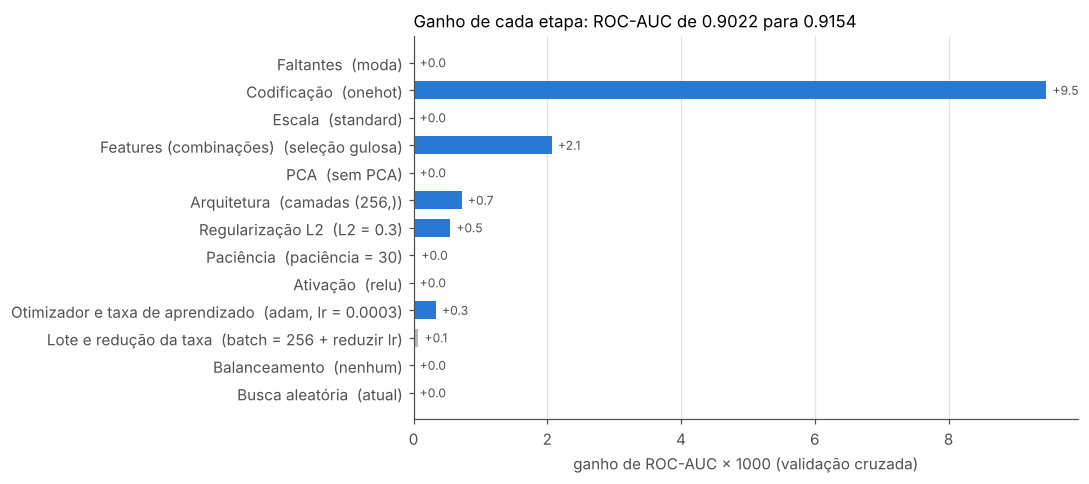

In [11]:
res = pd.read_csv("resultados/resultados_experimentos.csv")
etapas = [e for e in res["etapa"].unique() if not e.startswith(("4a", "4b"))]
melhor_por_etapa = (res[res["etapa"].isin(etapas)].sort_values("roc_auc", ascending=False)
                    .groupby("etapa", sort=False).head(1).set_index("etapa").loc[etapas])
ganho = melhor_por_etapa["roc_auc"].diff().fillna(0).iloc[1:]
nomes_etapas = [e.split(". ", 1)[1] for e in ganho.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
pos = np.arange(len(ganho))[::-1]
ax.barh(pos, ganho.values * 1000, color=[AZUL if g > 0.0001 else CINZA_CLARO for g in ganho.values], height=0.65)
escolhas = [f"camadas {e}" if e.startswith("(") else e for e in melhor_por_etapa["experimento"].iloc[1:]]
ax.set_yticks(pos, [f"{n}  ({e})" for n, e in zip(nomes_etapas, escolhas)])
for p, g in zip(pos, ganho.values):
    ax.annotate(f"+{g * 1000:.1f}", (g * 1000, p), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=8, color=CINZA_TEXTO)
ax.set(xlabel="ganho de ROC-AUC × 1000 (validação cruzada)",
       title=f"Ganho de cada etapa: ROC-AUC de {melhor_por_etapa['roc_auc'].iloc[0]:.4f} para {melhor_por_etapa['roc_auc'].iloc[-1]:.4f}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Análise:** dos +0,0132 de ROC-AUC conquistados na validação cruzada, **+0,0095 vieram da codificação *one-hot*** e +0,0021 do indicador de ganho/perda de capital — ou seja, 88% do ganho veio do tratamento dos dados. Arquitetura, regularização L2, taxa de aprendizado e lote somaram +0,0016. As demais etapas (faltantes, escala, PCA, paciência, ativação, balanceamento e a busca aleatória) não superaram a configuração que já existia.

## 2.2 Tratamento dos dados

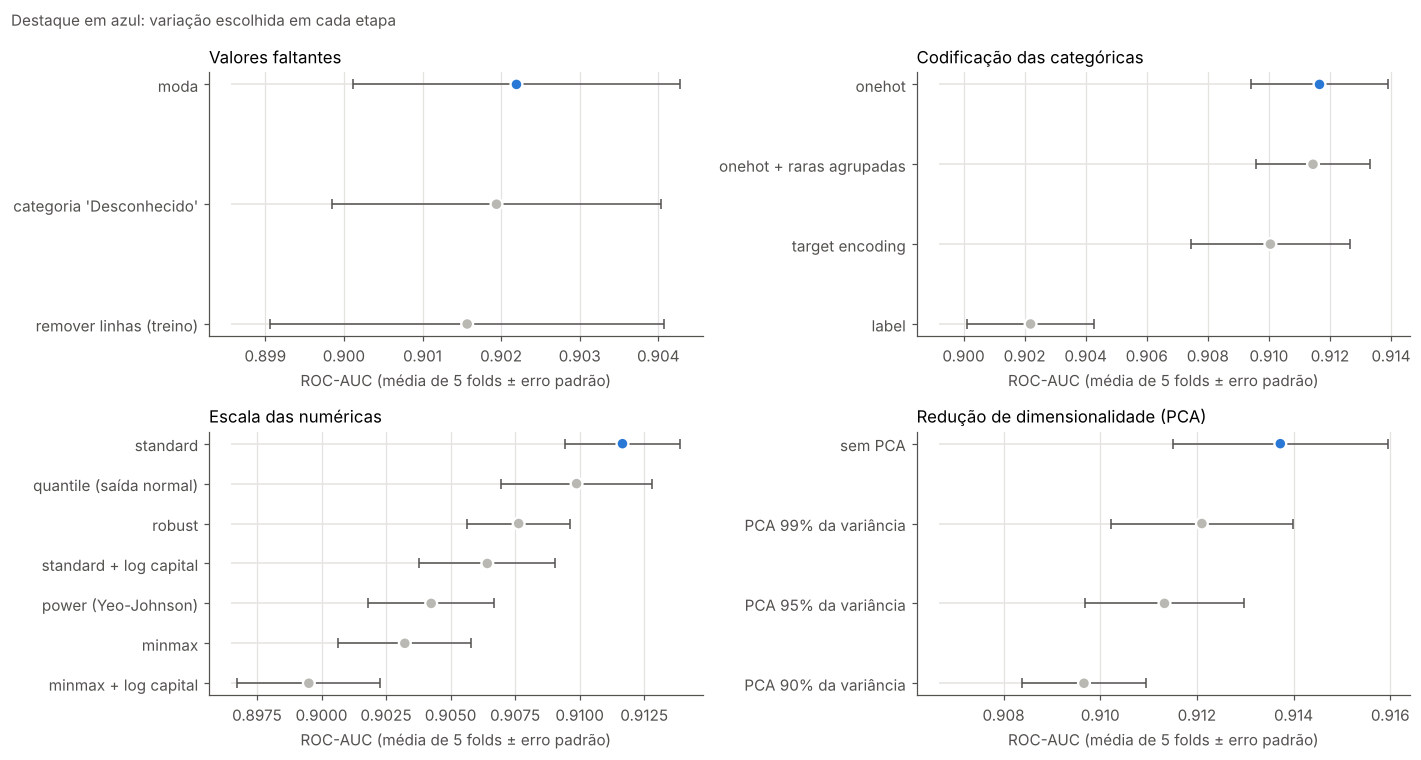

In [12]:
def painel(ax, etapa, titulo, renomear=None):
    t = res[res["etapa"] == etapa].sort_values("roc_auc")
    nomes = [renomear.get(e, e) if renomear else e for e in t["experimento"]]
    melhor = t["roc_auc"].idxmax()
    cores = [AZUL if i == melhor else CINZA_CLARO for i in t.index]
    pos = np.arange(len(t))
    ax.hlines(pos, t["roc_auc"].min() - 0.003, t["roc_auc"], color=CINZA_GRADE, lw=1)
    ax.errorbar(t["roc_auc"], pos, xerr=t["roc_auc_dp"] / np.sqrt(5), fmt="none", ecolor=CINZA_TEXTO, lw=1, capsize=3)
    ax.scatter(t["roc_auc"], pos, color=cores, s=60, zorder=3, edgecolor="white", linewidth=1.5)
    ax.set_yticks(pos, nomes)
    ax.set(title=titulo, xlabel="ROC-AUC (média de 5 folds ± erro padrão)")
    ax.grid(axis="y", visible=False)

fig, eixos = plt.subplots(2, 2, figsize=(13, 7))
painel(eixos[0, 0], "1. Faltantes", "Valores faltantes")
painel(eixos[0, 1], "2. Codificação", "Codificação das categóricas")
painel(eixos[1, 0], "3. Escala", "Escala das numéricas")
painel(eixos[1, 1], "5. PCA", "Redução de dimensionalidade (PCA)")
fig.suptitle("Destaque em azul: variação escolhida em cada etapa", x=0.01, ha="left", color=CINZA_TEXTO, fontsize=10)
plt.tight_layout()
plt.show()

**Análise:**

- **Faltantes:** as três opções têm intervalos que se sobrepõem quase totalmente — não há diferença real.
- **Codificação:** a única etapa de dados com uma diferença clara. O *one-hot* fica muito acima do `LabelEncoder` (0,9117 × 0,9022), com intervalos que não se sobrepõem.
- **Escala:** o `StandardScaler` foi o melhor. Com `MinMaxScaler`, os valores extremos de `capital.gain` (até 99.999) espremem os demais perto de zero.
- **PCA:** quanto menos componentes, pior. O PCA escolhe direções de maior variância sem olhar a renda e acaba descartando informação útil.

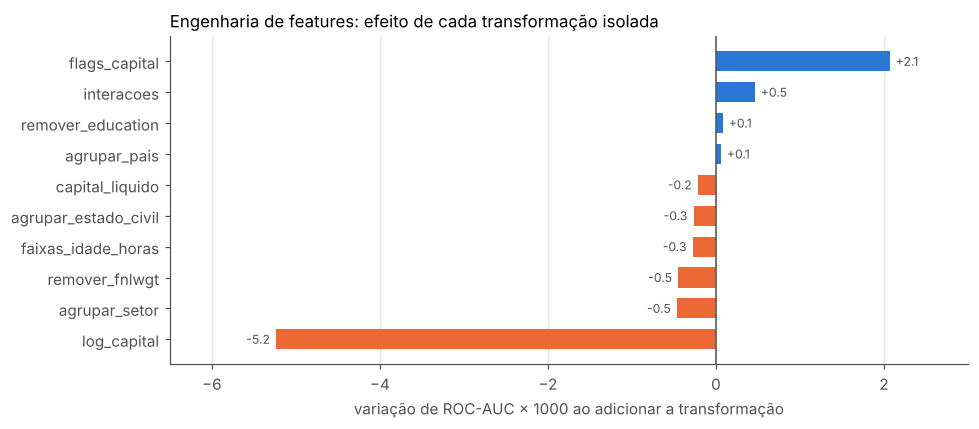

In [13]:
t = res[res["etapa"] == "4a. Features (uma a uma)"].set_index("experimento")["roc_auc"]
ganhos = (t.drop("atual") - t["atual"]).sort_values()
ganhos.index = ganhos.index.str.replace("+ ", "", regex=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ganhos.index, ganhos.values * 1000, color=[AZUL if g > 0 else LARANJA for g in ganhos.values], height=0.65)
ax.axvline(0, color=CINZA_TEXTO, lw=1)
for i, g in enumerate(ganhos.values):
    ax.annotate(f"{g * 1000:+.1f}", (g * 1000, i), xytext=(4 if g >= 0 else -4, 0), textcoords="offset points",
                va="center", ha="left" if g >= 0 else "right", fontsize=8, color=CINZA_TEXTO)
ax.set(xlabel="variação de ROC-AUC × 1000 ao adicionar a transformação",
       title="Engenharia de features: efeito de cada transformação isolada", xlim=(-6.5, 3))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Análise:** só o indicador de ganho/perda de capital trouxe um ganho claro (+2,1 × 10⁻³). O log das colunas de capital foi a pior mudança (−5,2 × 10⁻³), pelo motivo visto na seção 1.4. Agrupar categorias (país, estado civil, setor) ou criar faixas de idade/horas tira detalhes que a rede consegue aproveitar e, por isso, piora levemente o resultado.

## 2.3 Configuração da rede

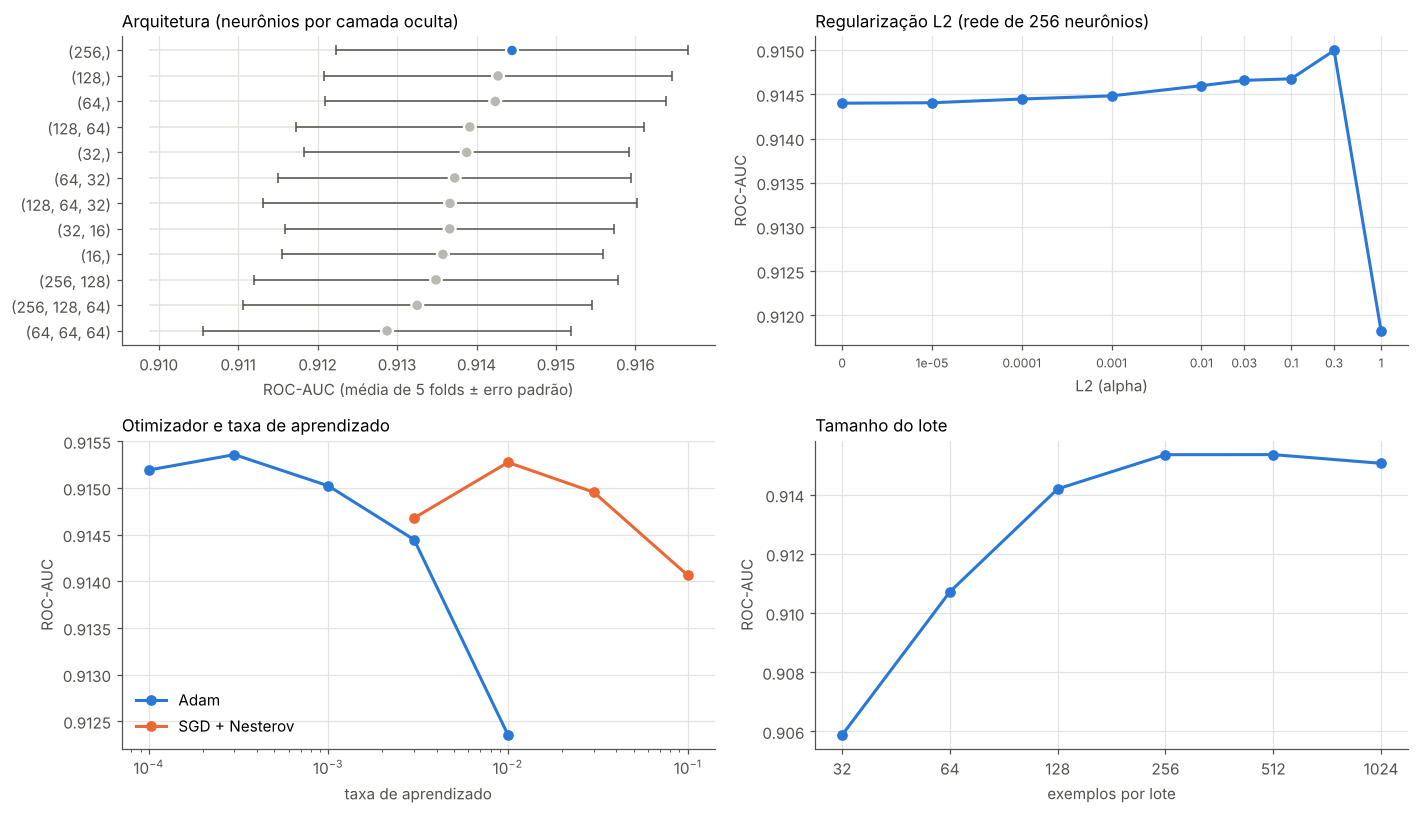

In [14]:
fig, eixos = plt.subplots(2, 2, figsize=(13, 7.5))

painel(eixos[0, 0], "6. Arquitetura", "Arquitetura (neurônios por camada oculta)")

t = res[res["etapa"] == "7a. Regularização L2"].copy()
t["l2"] = t["experimento"].str.replace("L2 = ", "").astype(float).replace(0, 1e-6)
t = t.sort_values("l2")
ax = eixos[0, 1]
ax.plot(t["l2"], t["roc_auc"], color=AZUL, marker="o", markersize=6)
ax.set_xscale("log")
ax.set_xticks(t["l2"], ["0"] + [f"{v:g}" for v in t["l2"].iloc[1:]], rotation=0, fontsize=8)
ax.minorticks_off()
ax.set(title="Regularização L2 (rede de 256 neurônios)", xlabel="L2 (alpha)", ylabel="ROC-AUC")

t = res[res["etapa"] == "9a. Otimizador e taxa de aprendizado"].copy()
t["otim"] = t["experimento"].str.split(",").str[0]
t["lr"] = t["experimento"].str.split("= ").str[1].astype(float)
ax = eixos[1, 0]
for otim, cor, nome in [("adam", AZUL, "Adam"), ("sgd + nesterov", LARANJA, "SGD + Nesterov")]:
    s = t[t["otim"] == otim].sort_values("lr")
    ax.plot(s["lr"], s["roc_auc"], color=cor, marker="o", markersize=6, label=nome)
ax.set_xscale("log")
ax.set(title="Otimizador e taxa de aprendizado", xlabel="taxa de aprendizado", ylabel="ROC-AUC")
ax.legend(frameon=False)

t = res[(res["etapa"] == "9b. Lote e redução da taxa") & ~res["experimento"].str.contains("reduzir")].copy()
t["batch"] = t["experimento"].str.replace("batch = ", "").astype(int)
t = t.sort_values("batch")
ax = eixos[1, 1]
ax.plot(t["batch"], t["roc_auc"], color=AZUL, marker="o", markersize=6)
ax.set_xscale("log", base=2)
ax.set_xticks(t["batch"], t["batch"].astype(str))
ax.minorticks_off()
ax.set(title="Tamanho do lote", xlabel="exemplos por lote", ylabel="ROC-AUC")
plt.tight_layout()
plt.show()

**Análise:**

- **Arquitetura:** todas as redes ficam dentro dos intervalos umas das outras. Uma camada oculta já basta; redes mais profundas não ganham nada e sobreajustam mais rápido.
- **Regularização L2:** a ROC-AUC sobe devagar até L2 = 0,3 e despenca com L2 = 1, quando a penalidade é tão forte que a rede não consegue mais aprender (subajuste).
- **Taxa de aprendizado:** cada otimizador tem a sua faixa ideal — Adam entre 1e-4 e 1e-3 e SGD com Nesterov perto de 0,01. Taxas altas demais (Adam 0,01, SGD 0,1) pioram o resultado.
- **Lote:** lotes pequenos (32, 64) pioram bastante; de 256 a 1024 o resultado é estável.

Fora a L2 forte demais e os lotes pequenos, as diferenças entre configurações da rede são pequenas.

## 2.4 Balanceamento das classes

As técnicas de balanceamento quase não mudam a ROC-AUC, mas trocam precisão por recall no limiar 0,5.

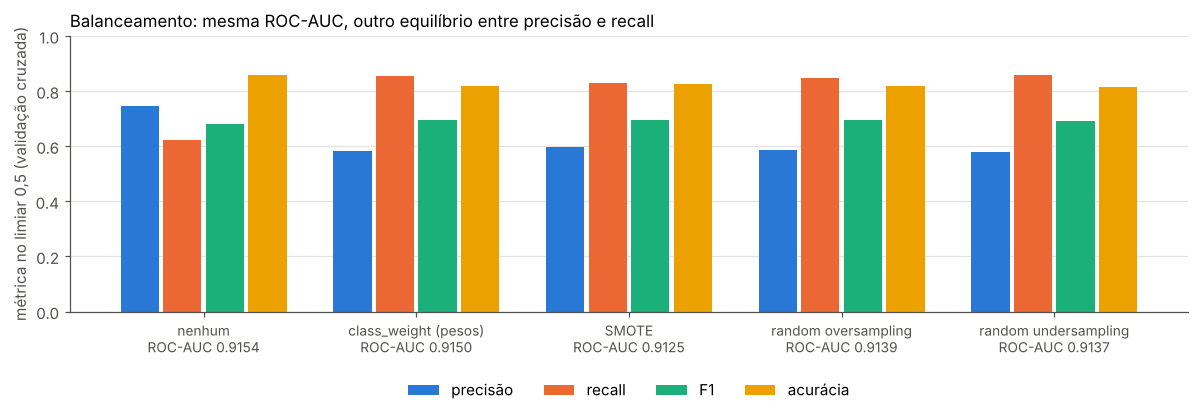

In [15]:
t = res[res["etapa"] == "10. Balanceamento"].set_index("experimento")
ordem = ["nenhum", "class_weight (pesos)", "SMOTE", "random oversampling", "random undersampling"]
t = t.loc[ordem]
metricas = [("precisao", "precisão", AZUL), ("recall", "recall", LARANJA), ("f1", "F1", VERDE_AGUA),
            ("acuracia", "acurácia", AMARELO)]
fig, ax = plt.subplots(figsize=(11, 4))
largura = 0.2
pos = np.arange(len(t))
for k, (col, nome, cor) in enumerate(metricas):
    ax.bar(pos + (k - 1.5) * largura, t[col], width=largura * 0.9, color=cor, label=nome)
ax.set_xticks(pos, [f"{e}\nROC-AUC {a:.4f}" for e, a in zip(t.index, t["roc_auc"])], fontsize=9)
ax.set(ylim=(0, 1), ylabel="métrica no limiar 0,5 (validação cruzada)",
       title="Balanceamento: mesma ROC-AUC, outro equilíbrio entre precisão e recall")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Análise:** com qualquer técnica de balanceamento, o recall sobe de 0,62 para 0,83–0,86, a precisão cai de 0,75 para 0,58–0,60, o F1 melhora pouco (0,68 → 0,69) e a acurácia cai (0,86 → 0,82). A ROC-AUC não melhora em nenhum caso. As técnicas só "empurram" as probabilidades para cima, o que equivale a baixar o limiar de decisão — e isso pode ser feito diretamente, como na próxima seção.

## 2.5 Modelo final no teste

O modelo final usa a melhor configuração da bancada (`bc.MELHOR_CONFIG`) e é a média de 5 redes treinadas com sementes diferentes. As previsões fora-do-fold da validação cruzada (dados de treino) são usadas para mostrar o efeito do limiar; o teste é usado para a avaliação.

In [16]:
pd.Series(bc.MELHOR_CONFIG, name="valor").to_frame()

,valor
faltantes,moda
features,"(flags_capital,)"
codificacao,onehot
escala,standard
pca,None
balanceamento,nenhum
camadas,"(256,)"
ativacao,relu
l2,0.3
otimizador,adam


In [17]:
# Previsões fora-do-fold da melhor configuração (lidas do cache da bancada, se existir)
bancada = bc.Bancada(X_treino, y_treino, n_folds=5, pasta_cache="resultados/cache")
bancada.melhor_cfg = dict(bc.MELHOR_CONFIG)
oof = bancada.oof_melhor()

# Modelo final: 5 redes com sementes diferentes, treinadas em todo o treino (em paralelo)
modelos = [(prep, rede) for prep, rede, _ in bc.treinar_sementes(X_treino, y_treino, bc.MELHOR_CONFIG, [0, 1, 2, 3, 4])]

def prever(X_):
    # probabilidade de renda > 50K: média das 5 redes
    return np.mean([bc.prever_proba(prep, rede, X_) for prep, rede in modelos], axis=0)

proba = prever(X_teste)
LIMIAR = bc.LIMIAR_F1
LIMIAR_TXT = f"{LIMIAR:.2f}".replace(".", ",")
tabela = pd.DataFrame({"limiar 0,5": bc.calcular_metricas(y_teste, proba, 0.5),
                       f"limiar {LIMIAR_TXT} (máx. F1)": bc.calcular_metricas(y_teste, proba, LIMIAR)}).T
tabela.round(4)

,acuracia,acuracia_bal,precisao,recall,f1,mcc,roc_auc,pr_auc,log_loss
"limiar 0,5",0.8658,0.7910,0.7601,0.6467,0.6988,0.6165,0.9212,0.8078,0.2939
"limiar 0,40 (máx. F1)",0.8575,0.8215,0.6863,0.7519,0.7176,0.6237,0.9212,0.8078,0.2939


**Análise:** no teste, a rede alcança **ROC-AUC 0,921 e PR-AUC 0,808**. No limiar 0,5 a acurácia é 0,866 e a precisão 0,760, mas o recall é de só 0,647. No limiar **0,40** (escolhido na validação, sem olhar o teste) o recall sobe para **0,752** e o F1 para **0,718**, com uma pequena perda de acurácia (0,858). O MCC, que resume a matriz de confusão inteira, também é maior no limiar 0,40 (0,6237 × 0,6165).

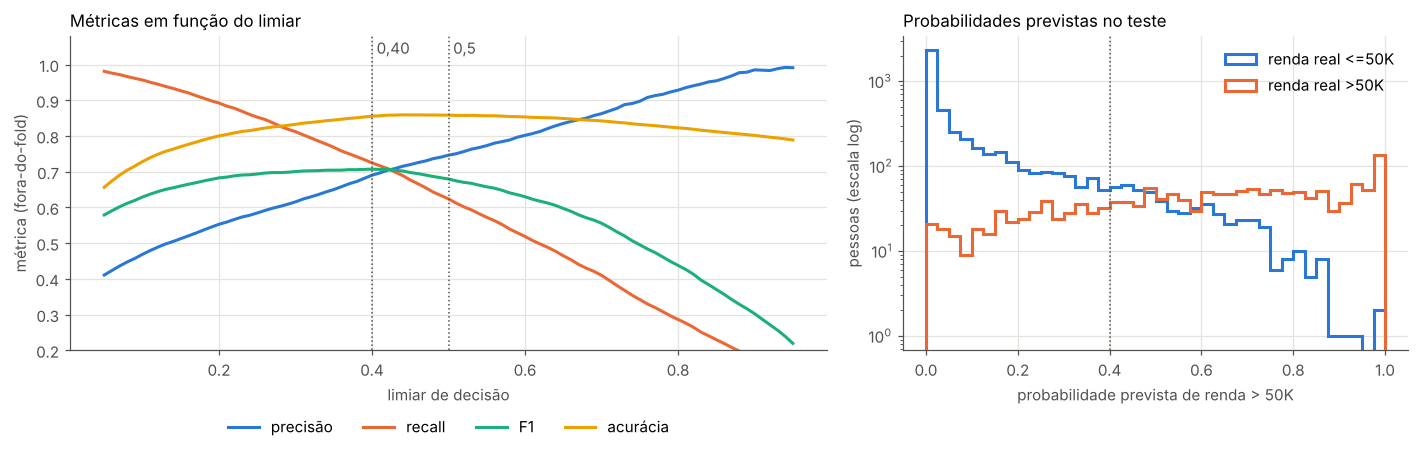

In [18]:
limiares = np.round(np.arange(0.05, 0.951, 0.01), 2)
curvas = pd.DataFrame([bc.calcular_metricas(y_treino, oof, t) for t in limiares], index=limiares)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [3, 2]})
ax = eixos[0]
for col, cor, nome in [("precisao", AZUL, "precisão"), ("recall", LARANJA, "recall"),
                       ("f1", VERDE_AGUA, "F1"), ("acuracia", AMARELO, "acurácia")]:
    ax.plot(curvas.index, curvas[col], color=cor, label=nome)
for lim, rot in [(0.5, "0,5"), (LIMIAR, LIMIAR_TXT)]:
    ax.axvline(lim, color=CINZA_TEXTO, lw=1, ls=":")
    ax.annotate(rot, (lim, 1.02), xytext=(3, 0), textcoords="offset points", va="bottom", color=CINZA_TEXTO)
ax.set(xlabel="limiar de decisão", ylabel="métrica (fora-do-fold)", ylim=(0.2, 1.08),
       title="Métricas em função do limiar")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.17))

ax = eixos[1]
bins = np.linspace(0, 1, 41)
for classe, rotulo in [(0, "<=50K"), (1, ">50K")]:
    ax.hist(proba[y_teste == classe], bins=bins, color=COR_CLASSE[rotulo], histtype="step", linewidth=2,
            label=f"renda real {rotulo}")
ax.axvline(LIMIAR, color=CINZA_TEXTO, lw=1, ls=":")
ax.set_yscale("log")
ax.set(xlabel="probabilidade prevista de renda > 50K", ylabel="pessoas (escala log)",
       title="Probabilidades previstas no teste")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Análise:**

- **Limiar (esquerda):** precisão e recall se cruzam perto de 0,40, onde o F1 é máximo. A acurácia é quase plana entre 0,3 e 0,6 (por volta de 0,85–0,86): mudar o limiar nessa faixa troca precisão por recall quase sem custo de acurácia.
- **Probabilidades (direita):** a maioria das pessoas `<=50K` recebe probabilidade perto de 0, e muitas `>50K` ficam perto de 1 (em geral, as de alto ganho de capital). Os erros se concentram na faixa intermediária, de 0,2 a 0,7, onde as duas classes se misturam.

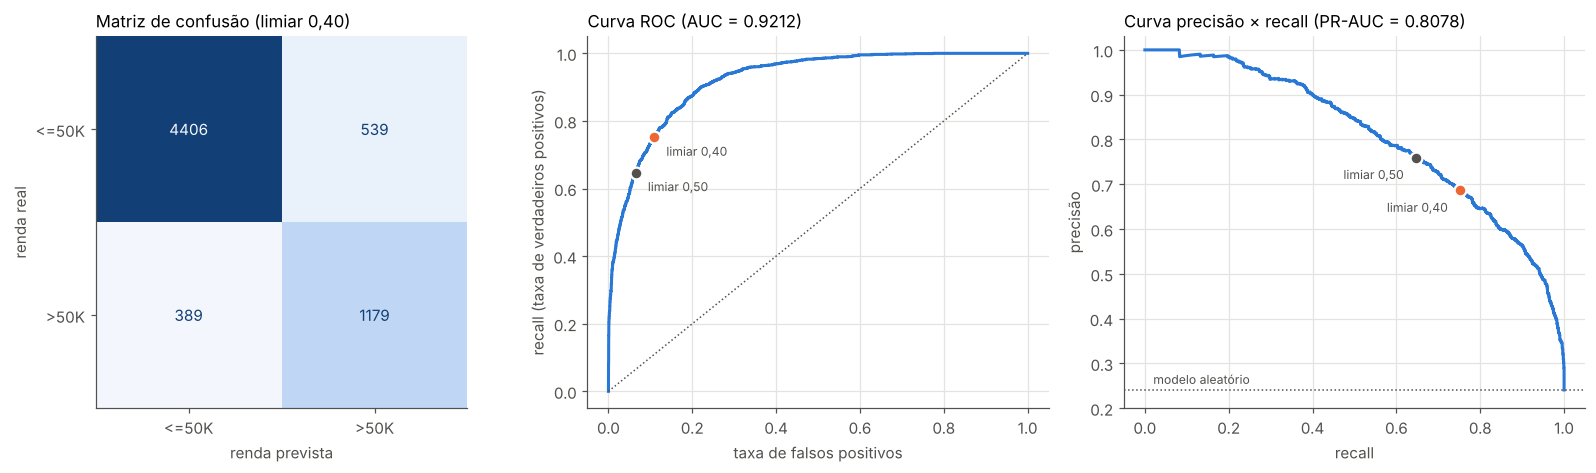

In [19]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.4))

ConfusionMatrixDisplay.from_predictions(y_teste, (proba >= LIMIAR).astype(int), display_labels=["<=50K", ">50K"],
                                        cmap=AZUIS, colorbar=False, ax=eixos[0])
eixos[0].grid(False)
eixos[0].set(title=f"Matriz de confusão (limiar {LIMIAR_TXT})", xlabel="renda prevista", ylabel="renda real")

fpr, tpr, lim_roc = roc_curve(y_teste, proba)
eixos[1].plot(fpr, tpr, color=AZUL)
eixos[1].plot([0, 1], [0, 1], color=CINZA_TEXTO, lw=1, ls=":")
for lim, cor in [(0.5, CINZA_TEXTO), (LIMIAR, LARANJA)]:
    i = np.argmin(np.abs(lim_roc - lim))
    eixos[1].scatter(fpr[i], tpr[i], s=60, color=cor, zorder=3, edgecolor="white", linewidth=1.5)
    eixos[1].annotate(f"limiar {lim:.2f}".replace(".", ","), (fpr[i], tpr[i]), xytext=(8, -12), textcoords="offset points",
                      fontsize=8, color=CINZA_TEXTO)
eixos[1].set(xlabel="taxa de falsos positivos", ylabel="recall (taxa de verdadeiros positivos)",
             title=f"Curva ROC (AUC = {roc_auc_score(y_teste, proba):.4f})")

prec, rec, lim_pr = precision_recall_curve(y_teste, proba)
eixos[2].plot(rec, prec, color=AZUL)
eixos[2].axhline(y_teste.mean(), color=CINZA_TEXTO, lw=1, ls=":")
eixos[2].annotate("modelo aleatório", (0.02, y_teste.mean()), xytext=(0, 4), textcoords="offset points",
                  fontsize=8, color=CINZA_TEXTO)
for lim, cor in [(0.5, CINZA_TEXTO), (LIMIAR, LARANJA)]:
    i = np.argmin(np.abs(lim_pr - lim))
    eixos[2].scatter(rec[i], prec[i], s=60, color=cor, zorder=3, edgecolor="white", linewidth=1.5)
    eixos[2].annotate(f"limiar {lim:.2f}".replace(".", ","), (rec[i], prec[i]), xytext=(-8, -14), textcoords="offset points",
                      fontsize=8, color=CINZA_TEXTO, ha="right")
eixos[2].set(xlabel="recall", ylabel="precisão", ylim=(0.2, 1.03),
             title=f"Curva precisão × recall (PR-AUC = {tabela['pr_auc'].iloc[0]:.4f})")
plt.tight_layout()
plt.show()

**Análise:** com limiar 0,40, a rede acerta 1.179 das 1.568 pessoas com renda `>50K` (recall de 75%) e erra 389. Entre as 1.718 pessoas que ela classifica como `>50K`, 539 são falsos positivos (precisão de 69%). Nas curvas, o ponto laranja (0,40) fica mais à direita do que o cinza (0,5): mais recall em troca de um pouco de precisão.

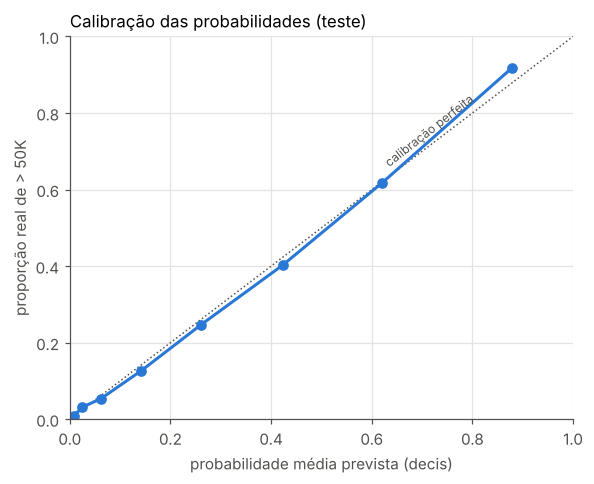

In [20]:
# Calibração: quando a rede diz "70%", cerca de 70% dessas pessoas ganham > 50K?
frac_real, prob_media = calibration_curve(y_teste, proba, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], color=CINZA_TEXTO, lw=1, ls=":")
ax.plot(prob_media, frac_real, color=AZUL, marker="o", markersize=6)
ax.annotate("calibração perfeita", (0.62, 0.66), rotation=38, fontsize=8, color=CINZA_TEXTO)
ax.set(xlabel="probabilidade média prevista (decis)", ylabel="proporção real de > 50K",
       title="Calibração das probabilidades (teste)", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
plt.show()

**Análise:** a curva fica muito perto da diagonal: quando a rede prevê 40%, cerca de 40% dessas pessoas realmente ganham `>50K`. As probabilidades são **bem calibradas** (efeito do treino com log loss e da regularização L2), então podem ser usadas diretamente como estimativas de chance — por exemplo, para escolher um limiar de acordo com o custo de cada tipo de erro. Só no decil mais alto a rede é um pouco conservadora (prevê 88% para um grupo com 92% de renda alta).

## 2.6 Desempenho por grupo

As métricas gerais podem esconder diferenças entre grupos de pessoas. Abaixo, precisão, recall e F1 no teste (limiar 0,40) por sexo, faixa de idade e raça.

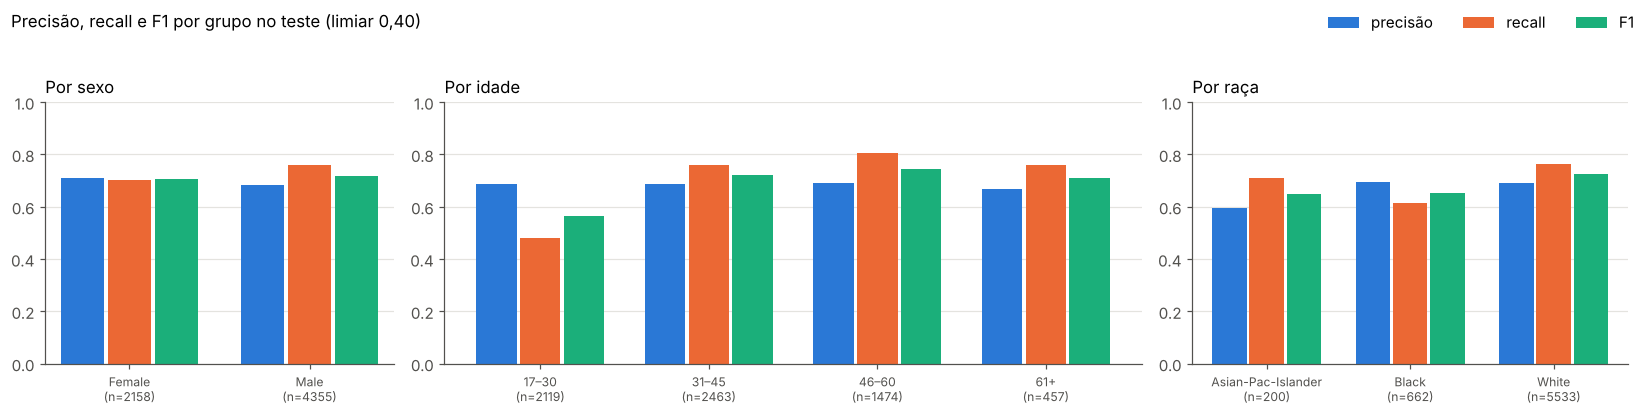

pessoas  % > 50K real  % > 50K previsto  precisao  recall     f1  acuracia
variável grupo                                                                                         
sexo     Female                 2158         0.114             0.112     0.711   0.702  0.706     0.934
         Male                   4355         0.304             0.339     0.682   0.761  0.720     0.820
idade    17–30                  2119         0.065             0.045     0.688   0.482  0.567     0.952
         31–45                  2463         0.305             0.337     0.686   0.759  0.721     0.821
         46–60                  1474         0.385             0.450     0.690   0.806  0.744     0.786
         61+                     457         0.247             0.282     0.667   0.761  0.711     0.847
raça     Asian-Pac-Islander      200         0.260             0.310     0.597   0.712  0.649     0.800
         Black                   662         0.140             0.124     0.695   0.613  0.651     0.908
         White                  5533         0.255             0.283     0.689   0.765  0.725     0.852

In [21]:
teste = X_teste.copy()
teste["y"], teste["pred"], teste["proba"] = y_teste, (proba >= LIMIAR).astype(int), proba
teste["faixa_idade"] = pd.cut(teste["age"], [16, 30, 45, 60, 91], labels=["17–30", "31–45", "46–60", "61+"])

def metricas_por_grupo(coluna, minimo=100):
    linhas = []
    for g, d in teste.groupby(coluna, observed=True):
        if len(d) < minimo or d["y"].sum() < 10:
            continue
        m = bc.calcular_metricas(d["y"].to_numpy(), d["proba"].to_numpy(), LIMIAR)
        linhas.append({"grupo": g, "pessoas": len(d), "% > 50K real": d["y"].mean(),
                       "% > 50K previsto": d["pred"].mean(), **{k: m[k] for k in ["precisao", "recall", "f1", "acuracia"]}})
    return pd.DataFrame(linhas).set_index("grupo")

grupos = {"sexo": metricas_por_grupo("sex"), "idade": metricas_por_grupo("faixa_idade"),
          "raça": metricas_por_grupo("race")}
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [2, 4, 2.5]})
for ax, (nome, t) in zip(eixos, grupos.items()):
    pos = np.arange(len(t))
    for k, (col, rot, cor) in enumerate([("precisao", "precisão", AZUL), ("recall", "recall", LARANJA), ("f1", "F1", VERDE_AGUA)]):
        ax.bar(pos + (k - 1) * 0.26, t[col], width=0.24, color=cor, label=rot)
    ax.set_xticks(pos, [f"{g}\n(n={n})" for g, n in zip(t.index, t["pessoas"])], fontsize=8)
    ax.set(title=f"Por {nome}", ylim=(0, 1))
    ax.grid(axis="x", visible=False)
fig.legend(*eixos[0].get_legend_handles_labels(), frameon=False, ncol=3, loc="upper right")
fig.suptitle(f"Precisão, recall e F1 por grupo no teste (limiar {LIMIAR_TXT})", x=0.01, ha="left", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
pd.concat(grupos, names=["variável", "grupo"]).round(3)

**Análise:**

- **Sexo:** o F1 é parecido (0,71 mulheres × 0,72 homens), e a proporção prevista de `>50K` acompanha a real nos dois grupos (11,2% × 11,4% para mulheres; 33,9% × 30,4% para homens). A acurácia das mulheres é bem maior (0,93 × 0,82), mas só porque apenas 11% delas têm renda alta — é mais fácil acertar quando quase todos são `<=50K`.
- **Idade:** o modelo vai mal com **jovens de 17 a 30 anos**: recall de 0,48 e F1 de 0,57. Só 6,5% deles ganham `>50K`, e a rede prevê ainda menos (4,5%). O melhor desempenho é na faixa de 46 a 60 anos (F1 0,74).
- **Raça:** o recall para pessoas negras (0,61) é menor que para brancas (0,77): a rede encontra menos as pessoas negras de renda alta. O grupo asiático tem precisão mais baixa (0,60), mas a amostra é pequena (200 pessoas, 52 com renda alta).

Essas diferenças vêm, em parte, dos padrões e desigualdades do próprio censo. Se o modelo fosse usado para decisões reais, elas precisariam ser avaliadas com cuidado.

# Parte 3 — Importância das features

Uma rede neural não tem um "coeficiente" por variável como a regressão logística, e a variável original vira várias entradas (cada categoria do *one-hot*, os indicadores de capital…). Por isso usamos métodos que tratam o modelo como uma caixa-preta e trabalham sobre as **14 colunas originais**:

1. **Importância por permutação:** embaralhamos os valores de uma coluna no teste (quebrando a relação dela com a renda) e medimos quanto a métrica piora. Quanto maior a piora, mais o modelo depende daquela coluna. Repetimos 10 vezes para medir a variação.
2. **Permutação por grupos:** colunas que carregam a mesma informação (ex.: `education` e `education.num`) se "cobrem" uma à outra; embaralhando juntas, vemos a importância da informação como um todo.
3. **Dependência parcial:** como a probabilidade prevista muda quando alteramos o valor de uma variável, mantendo todo o resto igual.

In [22]:
rng = np.random.default_rng(RANDOM_STATE)
N_REPETICOES = 10
COLUNAS = list(X_teste.columns)

def metricas_resumo(p):
    return {"roc_auc": roc_auc_score(y_teste, p),
            "f1": f1_score(y_teste, (p >= LIMIAR).astype(int)),
            "acuracia": ((p >= 0.5).astype(int) == y_teste).mean()}

base = metricas_resumo(proba)

def importancia_permutacao(grupos):
    linhas = []
    for nome, colunas in grupos.items():
        for r in range(N_REPETICOES):
            Xp = X_teste.copy()
            ordem = rng.permutation(len(Xp))
            Xp[colunas] = X_teste[colunas].to_numpy()[ordem]   # mesma permutação para todo o grupo
            m = metricas_resumo(prever(Xp))
            linhas.append({"feature": nome, **{k: base[k] - m[k] for k in base}})
    return pd.DataFrame(linhas)

perm = importancia_permutacao({c: [c] for c in COLUNAS})
resumo_perm = perm.groupby("feature").agg(["mean", "std"])
resumo_perm.columns = [f"{a}_{b}" for a, b in resumo_perm.columns]
resumo_perm = resumo_perm.sort_values("roc_auc_mean", ascending=False)
resumo_perm.round(4)

,roc_auc_mean,roc_auc_std,f1_mean,f1_std,acuracia_mean,acuracia_std
feature,,,,,,
marital.status,0.0568,0.0025,0.0923,0.0056,0.0294,0.0030
capital.gain,0.0442,0.0010,0.0631,0.0020,0.0388,0.0016
education.num,0.0308,0.0022,0.0648,0.0059,0.0313,0.0028
age,0.0300,0.0020,0.0582,0.0058,0.0188,0.0022
hours.per.week,0.0163,0.0016,0.0235,0.0047,0.0096,0.0019
occupation,0.0140,0.0009,0.0320,0.0034,0.0158,0.0022
relationship,0.0090,0.0010,0.0215,0.0036,0.0090,0.0021
sex,0.0058,0.0007,0.0120,0.0024,0.0058,0.0013
capital.loss,0.0053,0.0007,0.0108,0.0018,0.0059,0.0013


**Análise:** a coluna mais importante para a ROC-AUC é `marital.status` (queda de 0,057 ao embaralhá-la), seguida de `capital.gain` (0,044), `education.num` (0,031) e `age` (0,030). Depois vêm `hours.per.week` (0,016) e `occupation` (0,014). `fnlwgt`, `race`, `native.country` e `education` têm importância praticamente nula.

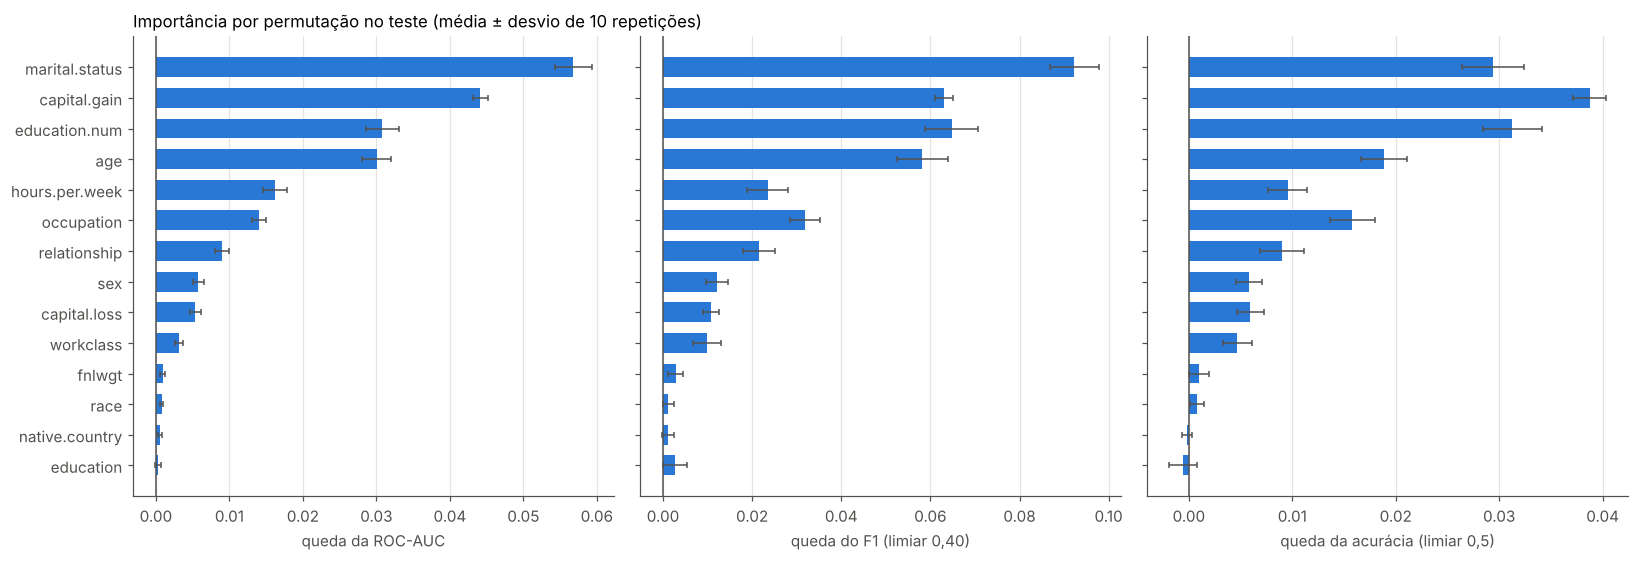

In [23]:
ordem = resumo_perm.index[::-1]
fig, eixos = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, (met, nome, escala) in zip(eixos, [("roc_auc", "queda da ROC-AUC", 1), ("f1", f"queda do F1 (limiar {LIMIAR_TXT})", 1),
                                           ("acuracia", "queda da acurácia (limiar 0,5)", 1)]):
    m = resumo_perm.loc[ordem, f"{met}_mean"] * escala
    s = resumo_perm.loc[ordem, f"{met}_std"] * escala
    ax.barh(ordem, m, xerr=s, color=AZUL, height=0.65, error_kw={"ecolor": CINZA_TEXTO, "lw": 1, "capsize": 2})
    ax.axvline(0, color=CINZA_TEXTO, lw=1)
    ax.set(xlabel=nome)
    ax.grid(axis="y", visible=False)
eixos[0].set_title("Importância por permutação no teste (média ± desvio de 10 repetições)")
plt.tight_layout()
plt.show()

**Análise:**

- **As três métricas concordam nas quatro variáveis principais.** Na acurácia, `capital.gain` passa para o primeiro lugar: os altos ganhos de capital geram as previsões mais confiantes (probabilidade perto de 1), e embaralhá-los transforma acertos certos em erros.
- **`education` tem importância zero, mas não porque escolaridade não importe:** `education.num` carrega exatamente a mesma informação, e a rede usa as duas. Ao embaralhar só `education`, a rede ainda tem `education.num`.
- Pelo mesmo motivo, `relationship` aparece em 7º lugar, embora seja a variável mais associada à renda (seção 1.7): grande parte da sua informação está em `marital.status` e `sex`.
- **`race` e `native.country` quase não influenciam a rede** (queda abaixo de 0,001). Já `sex` tem algum peso direto (0,006), além do que entra indiretamente por `relationship` (`Husband`/`Wife`).

In [24]:
GRUPOS = {
    "escolaridade (education + education.num)": ["education", "education.num"],
    "família (relationship + marital.status)": ["relationship", "marital.status"],
    "família + sexo": ["relationship", "marital.status", "sex"],
    "capital (capital.gain + capital.loss)": ["capital.gain", "capital.loss"],
}
perm_g = importancia_permutacao(GRUPOS).groupby("feature")["roc_auc"].agg(["mean", "std"])
individual = {g: resumo_perm.loc[cols, "roc_auc_mean"].sum() for g, cols in GRUPOS.items()}
comparacao = pd.DataFrame({"queda ROC-AUC (grupo embaralhado junto)": perm_g["mean"],
                           "soma das quedas individuais": pd.Series(individual)}).loc[list(GRUPOS)]
comparacao.round(4)

,queda ROC-AUC (grupo embaralhado junto),soma das quedas individuais
escolaridade (education + education.num),0.0338,0.0311
família (relationship + marital.status),0.0940,0.0658
família + sexo,0.1138,0.0716
capital (capital.gain + capital.loss),0.0483,0.0495


**Análise:** quando colunas redundantes são embaralhadas **juntas**, a importância real da informação aparece:

- **Situação familiar** (`relationship` + `marital.status`): queda de 0,094 — bem mais que a soma das quedas individuais (0,066), porque, embaralhando uma coluna de cada vez, a outra "cobre" a informação perdida. Com `sex`, a queda chega a 0,114: **a situação familiar é, de longe, a informação mais importante para a rede.**
- **Escolaridade** (`education` + `education.num`): 0,034, um pouco acima da soma individual (0,031).
- **Capital** (`capital.gain` + `capital.loss`): 0,048, praticamente igual à soma (0,050). Essas colunas trazem informações independentes, sem redundância.

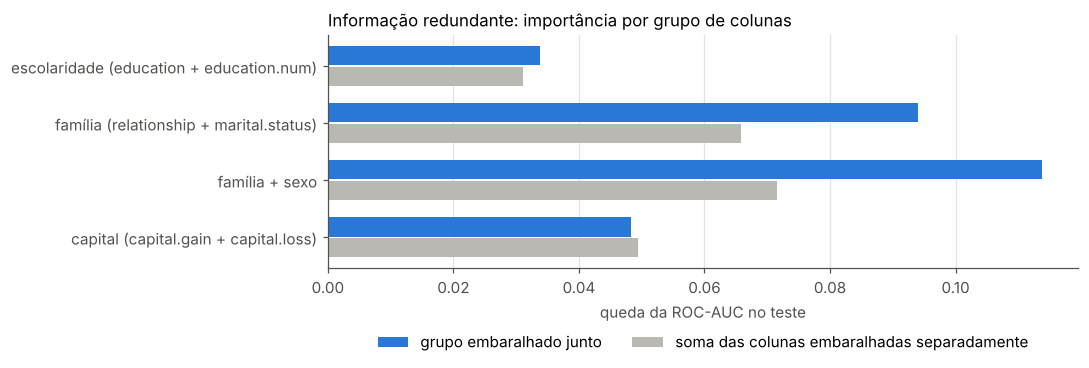

In [25]:
fig, ax = plt.subplots(figsize=(10, 3.6))
pos = np.arange(len(comparacao))[::-1]
ax.barh(pos + 0.18, comparacao.iloc[:, 0], height=0.34, color=AZUL, label="grupo embaralhado junto")
ax.barh(pos - 0.18, comparacao.iloc[:, 1], height=0.34, color=CINZA_CLARO, label="soma das colunas embaralhadas separadamente")
ax.set_yticks(pos, comparacao.index)
ax.set(xlabel="queda da ROC-AUC no teste", title="Informação redundante: importância por grupo de colunas")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3.1 Dependência parcial: como cada variável muda a previsão

Para uma amostra de 1.000 pessoas do teste, trocamos o valor de uma variável por cada valor de uma grade (mantendo o resto igual) e calculamos a probabilidade média prevista. As linhas finas mostram 40 pessoas individualmente (ICE), para ver se o efeito é o mesmo para todos.

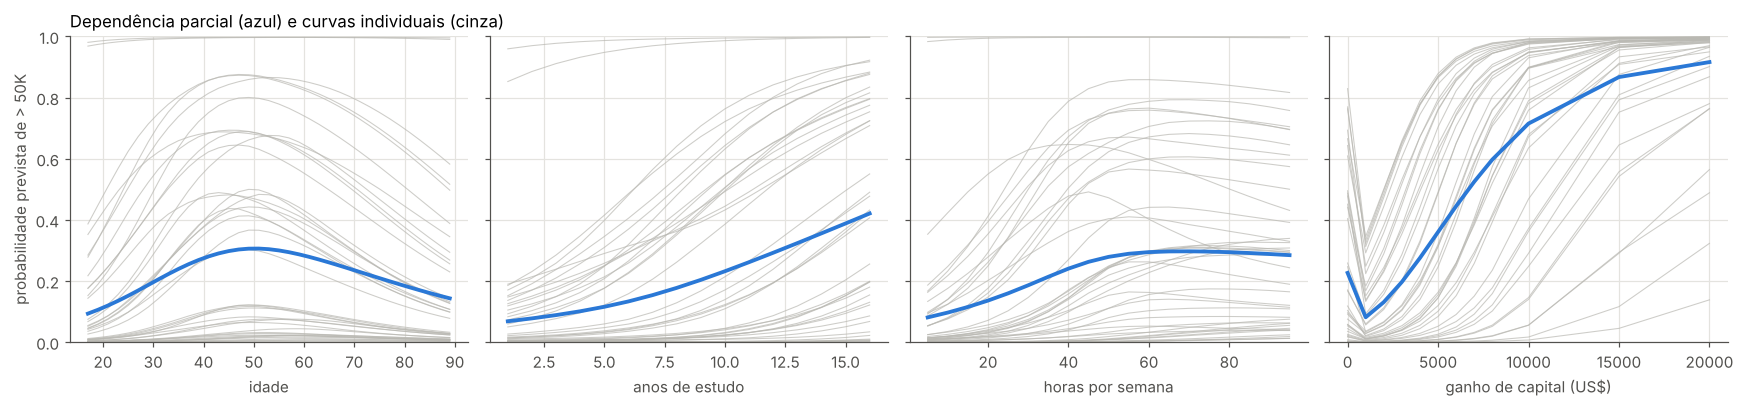

In [26]:
amostra = X_teste.sample(1000, random_state=RANDOM_STATE)
ice_idx = np.arange(40)

def dependencia(coluna, grade):
    curvas = []
    for v in grade:
        Xg = amostra.copy()
        Xg[coluna] = v
        curvas.append(prever(Xg))
    return np.array(curvas)  # (valores da grade, pessoas)

numericas = [("age", np.arange(17, 91, 2), "idade"),
             ("education.num", np.arange(1, 17), "anos de estudo"),
             ("hours.per.week", np.arange(5, 100, 5), "horas por semana"),
             ("capital.gain", np.array([0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 10000, 15000, 20000]), "ganho de capital (US$)")]
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (col, grade, rotulo) in zip(eixos, numericas):
    c = dependencia(col, grade)
    ax.plot(grade, c[:, ice_idx], color=CINZA_CLARO, lw=0.7, alpha=0.7)
    ax.plot(grade, c.mean(axis=1), color=AZUL, lw=2.5)
    ax.set(xlabel=rotulo, ylim=(0, 1))
eixos[0].set_ylabel("probabilidade prevista de > 50K")
eixos[0].set_title("Dependência parcial (azul) e curvas individuais (cinza)")
plt.tight_layout()
plt.show()

**Análise:**

- **Idade:** efeito em "U invertido". A probabilidade média sobe de 0,10 aos 17 anos para 0,31 por volta dos 50 e volta a cair para 0,15 aos 90.
- **Anos de estudo:** efeito crescente e contínuo, de 0,07 (1 ano) a 0,42 (16 anos).
- **Horas por semana:** sobe até cerca de 55 horas e depois se estabiliza — trabalhar ainda mais não aumenta a chance.
- **Ganho de capital:** a rede aprendeu os degraus vistos na seção 1.4. Ganhos pequenos (1.000 dólares) **reduzem** a probabilidade (de 0,23 para 0,08), e acima de 5.000 dólares ela sobe rapidamente, chegando a 0,72 com 10.000 e a 0,92 com 20.000.
- **Curvas individuais (cinza):** o efeito não é igual para todos. Para algumas pessoas as curvas ficam coladas em zero (o perfil delas indica renda baixa, qualquer que seja a idade ou o estudo); para outras, a mesma mudança leva a probabilidade de 0,2 a 0,8. É a rede modelando interações entre as variáveis.

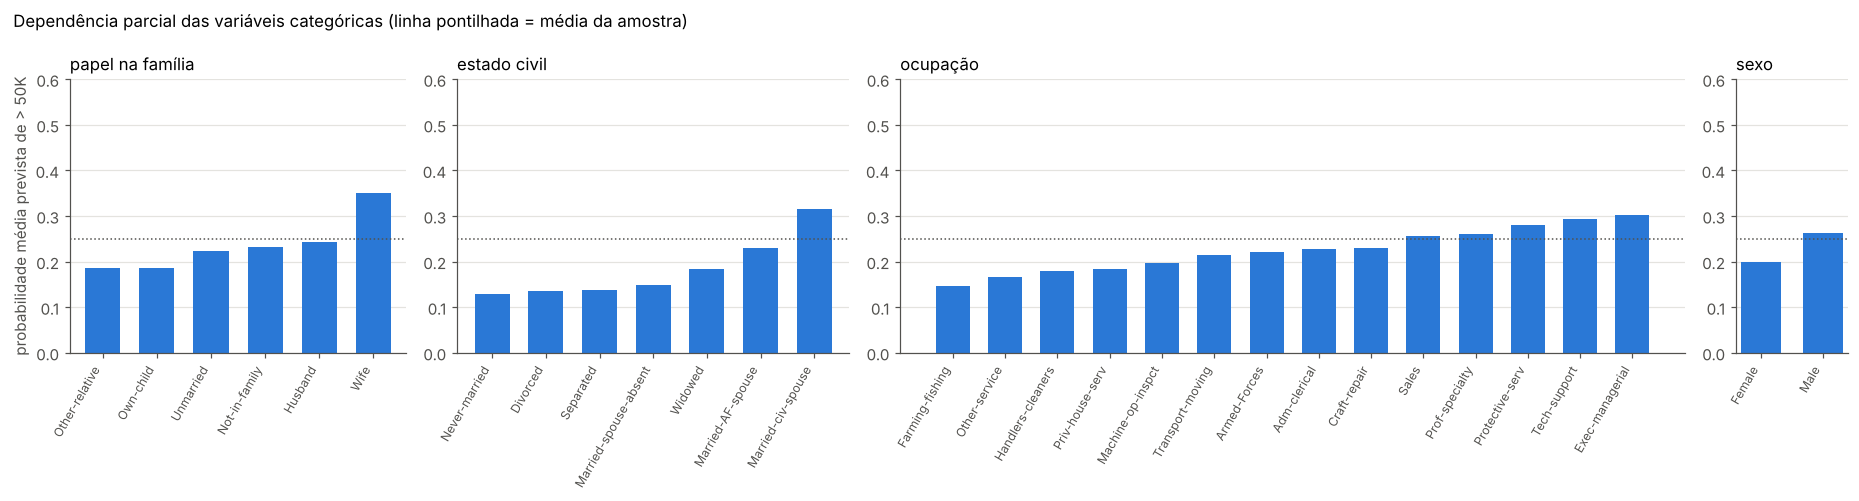

In [27]:
categoricas = [("relationship", "papel na família"), ("marital.status", "estado civil"),
               ("occupation", "ocupação"), ("sex", "sexo")]
fig, eixos = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [6, 7, 14, 2]})
for ax, (col, rotulo) in zip(eixos, categoricas):
    valores = X_treino[col].value_counts().index
    efeito = pd.Series({v: dependencia(col, [v]).mean() for v in valores}).sort_values()
    ax.bar(range(len(efeito)), efeito.values, color=AZUL, width=0.65)
    ax.axhline(proba[X_teste.index.isin(amostra.index)].mean(), color=CINZA_TEXTO, ls=":", lw=1)
    ax.set_xticks(range(len(efeito)), efeito.index, rotation=60, ha="right", fontsize=8)
    ax.set(title=rotulo, ylim=(0, max(0.6, efeito.max() * 1.15)))
    ax.grid(axis="x", visible=False)
eixos[0].set_ylabel("probabilidade média prevista de > 50K")
fig.suptitle("Dependência parcial das variáveis categóricas (linha pontilhada = média da amostra)",
             x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

**Análise:** mantendo todo o resto igual, ser `Wife` eleva a probabilidade média para 0,35 (contra 0,19 para `Own-child`); ser casado (`Married-civ-spouse`) para 0,32 (contra 0,13 para `Never-married`); e ser gestor (`Exec-managerial`) para 0,30 (contra 0,15 para `Farming-fishing`). O efeito do sexo, isolado das demais variáveis, é menor do que a diferença bruta nos dados (0,26 homens × 0,20 mulheres, contra 31% × 11% na seção 1.5), porque parte da diferença bruta vem de outras características ligadas ao sexo (estado civil, ocupação, horas trabalhadas).

Em geral, os efeitos isolados são menores que as diferenças brutas da Parte 1: lá, cada proporção mistura vários fatores (por exemplo, `Own-child` são, em geral, jovens solteiros), e aqui a dependência parcial isola o efeito de uma variável só.

# Conclusões

**Sobre o dataset**

- A renda alta é minoria (24%) e depende principalmente da **situação familiar** (casados), da **escolaridade**, da **idade** (pico entre 45 e 55 anos), do **ganho de capital** (em degraus) e da **ocupação**.
- Há bastante informação redundante (`education` = `education.num`; `relationship` ligada a `marital.status` e a `sex`) e variáveis quase sem relação com a renda (`fnlwgt`, `native.country`, `race`).
- As relações são não lineares e com interações (idade × escolaridade; degraus no capital), o que favorece modelos flexíveis como redes neurais — desde que as categóricas sejam codificadas com *one-hot*.

**Sobre os resultados**

- A codificação *one-hot* e o indicador de ganho de capital trouxeram quase todo o ganho da bancada; os hiperparâmetros da rede trouxeram ganhos pequenos.
- No teste: ROC-AUC 0,921, PR-AUC 0,808, acurácia 0,866 (limiar 0,5) e, no limiar 0,40, F1 0,718 com recall 0,752.
- As probabilidades são bem calibradas; o limiar pode ser escolhido de acordo com o custo de cada tipo de erro.
- O desempenho é pior para jovens (recall de 0,48) e o recall é menor para pessoas negras — pontos de atenção se o modelo fosse usado na prática.

**Sobre a importância das features**

- Por permutação: `marital.status` > `capital.gain` > `education.num` ≈ `age` > `hours.per.week` > `occupation`.
- Considerando a redundância, a **situação familiar** (`relationship` + `marital.status` + `sex`) é a informação mais importante, seguida do capital e da escolaridade.
- A rede aprendeu os padrões vistos na análise exploratória: o "U invertido" da idade, o crescimento com a escolaridade, a saturação das horas trabalhadas e os degraus do ganho de capital.